# Public data experiments
This is the notebook to run the public data experiment

In [1]:
import sys
from pathlib import Path

# Add the workspace root to sys.path
workspace_root = Path("/Users/eduardohome/workspace/benchmark_credit_scoring")
if str(workspace_root) not in sys.path:
    sys.path.insert(0, str(workspace_root))

# Now you can import from src
from src.utils.csv_config import read_csv_by_name, create_imbalanced_datasets, merge_xai_results
from src.model.functions import save_model, load_model, get_split_data
from src.xai.functions import get_train_iterations_shap, compute_xai_metrics_from_shap
from src.graph.functions import plot_model_boxplot, plot_imbalance_boxplot_grid, load_xai_file, plot_models_by_imbalance

try:
    from src.model.functions import get_train_model
except Exception as exc:
    # provide helpful message if import fails
    print("Failed to import model utilities:", exc)
    print("This often means a missing dependency such as libomp for LightGBM.")
    print("On macOS you can install it with `brew install libomp` and then restart the kernel.")
    raise

# General imports
import pandas as pd
from pathlib import Path

In [2]:
# -------------------------
# Settings
# -------------------------
data_dir = Path("/Users/eduardohome/workspace/benchmark_credit_scoring/data")
#datasets_to_run = ["australian", "german", "japan", "kgccdea", "taiwan", "th02", "kggmsc"]
datasets_to_run = ["australian", "german", "japan", "kgccdea", "th02"]
target_col = "target"

# Edit this list whenever you want more/less imbalance datasets
imbalance_levels = [10, 15, 20, 25]
n_iterations = 100
percentage = 90

# list of estimators understood by functions.get_model
model_choices = ["XGBoost", "LightGBM", "RandomForest", "BoostDT", "BoostSGB", "BagNN", "ANN"]
product = "default"

## Read data - Local Interpretability metrics

In [3]:
df_local = load_xai_file(
    data_dir=data_dir,
    dataset_name=datasets_to_run,
    file_type="all_models_resume_local",
)
df_local

,index,rankstab_local,rankstab_local_weight,dataset,imbalance,model
0,1,0.313662,0.110273,australian,10,XGBoost
1,2,0.299365,0.111697,australian,10,XGBoost
2,5,0.321101,0.110010,australian,10,XGBoost
3,10,0.279712,0.093580,australian,10,XGBoost
4,11,0.320741,0.110059,australian,10,XGBoost
...,...,...,...,...,...,...
55819,1189,0.384207,0.153177,th02,25,ANN
55820,1191,0.333856,0.122401,th02,25,ANN
55821,1195,0.490744,0.199409,th02,25,ANN
55822,1198,0.327609,0.111915,th02,25,ANN


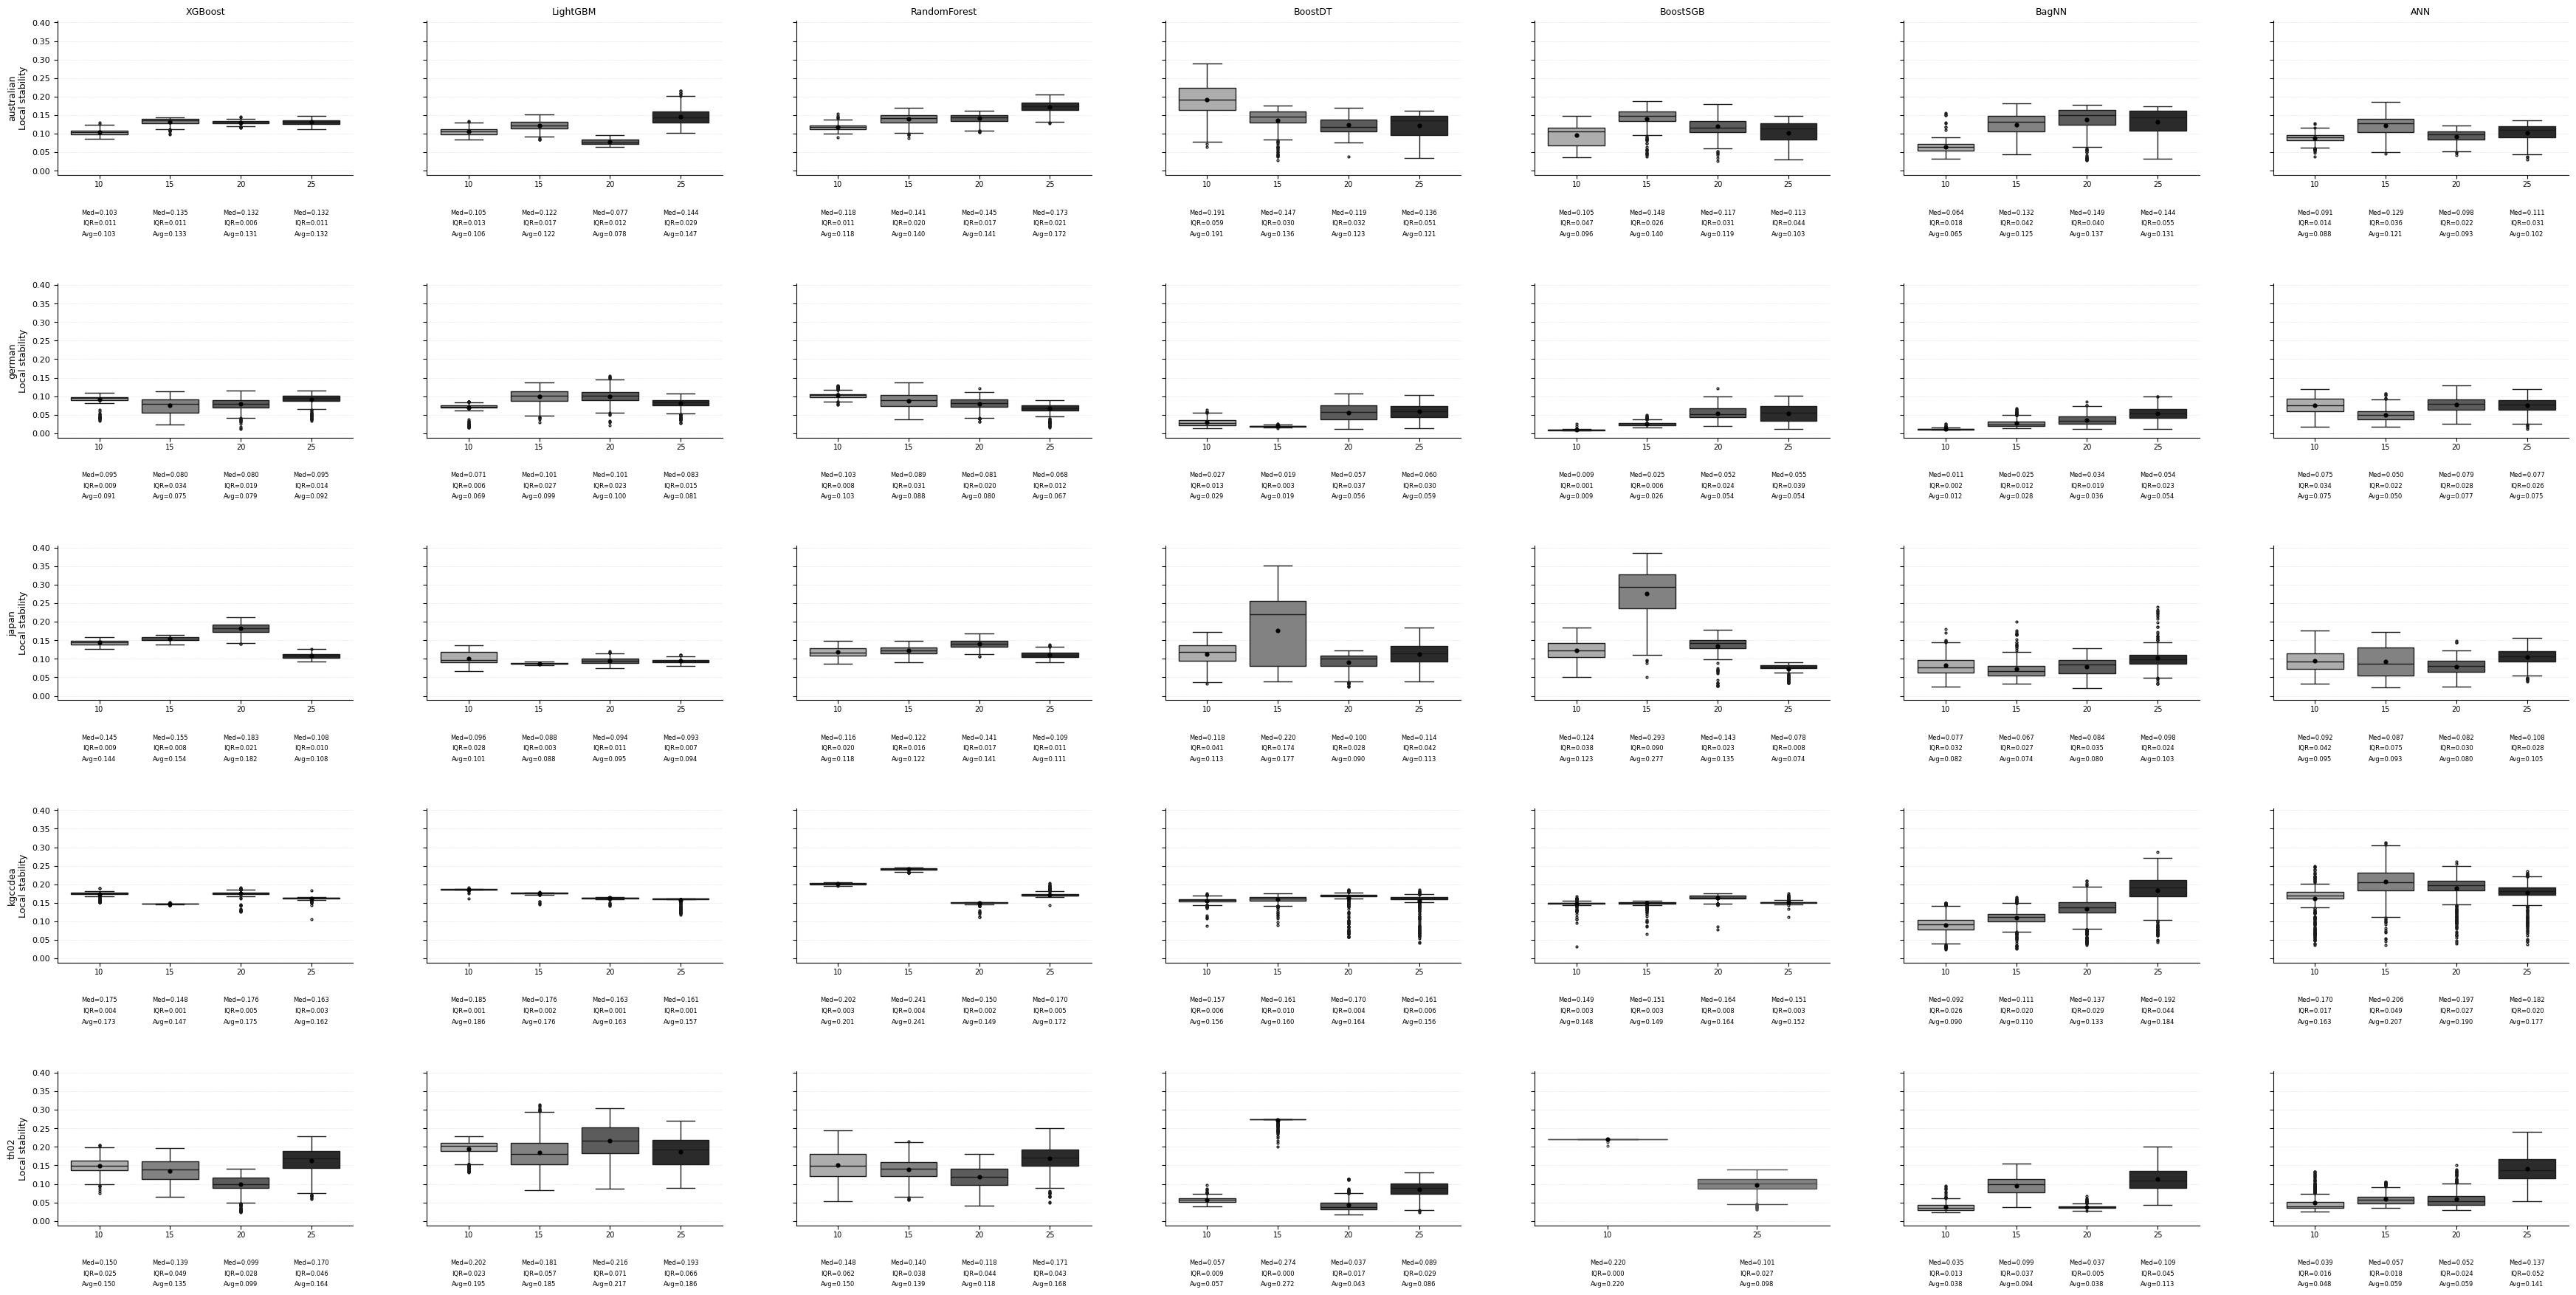

In [4]:
import matplotlib.pyplot as plt

fig, axes = plot_imbalance_boxplot_grid(
    df=df_local,
    datasets=datasets_to_run,
    models=model_choices,
    metric="rankstab_local_weight",
    ylabel="Local stability",
    xlabel="",
    imbalance_order=imbalance_levels,
    suptitle=f""
)

plt.show()


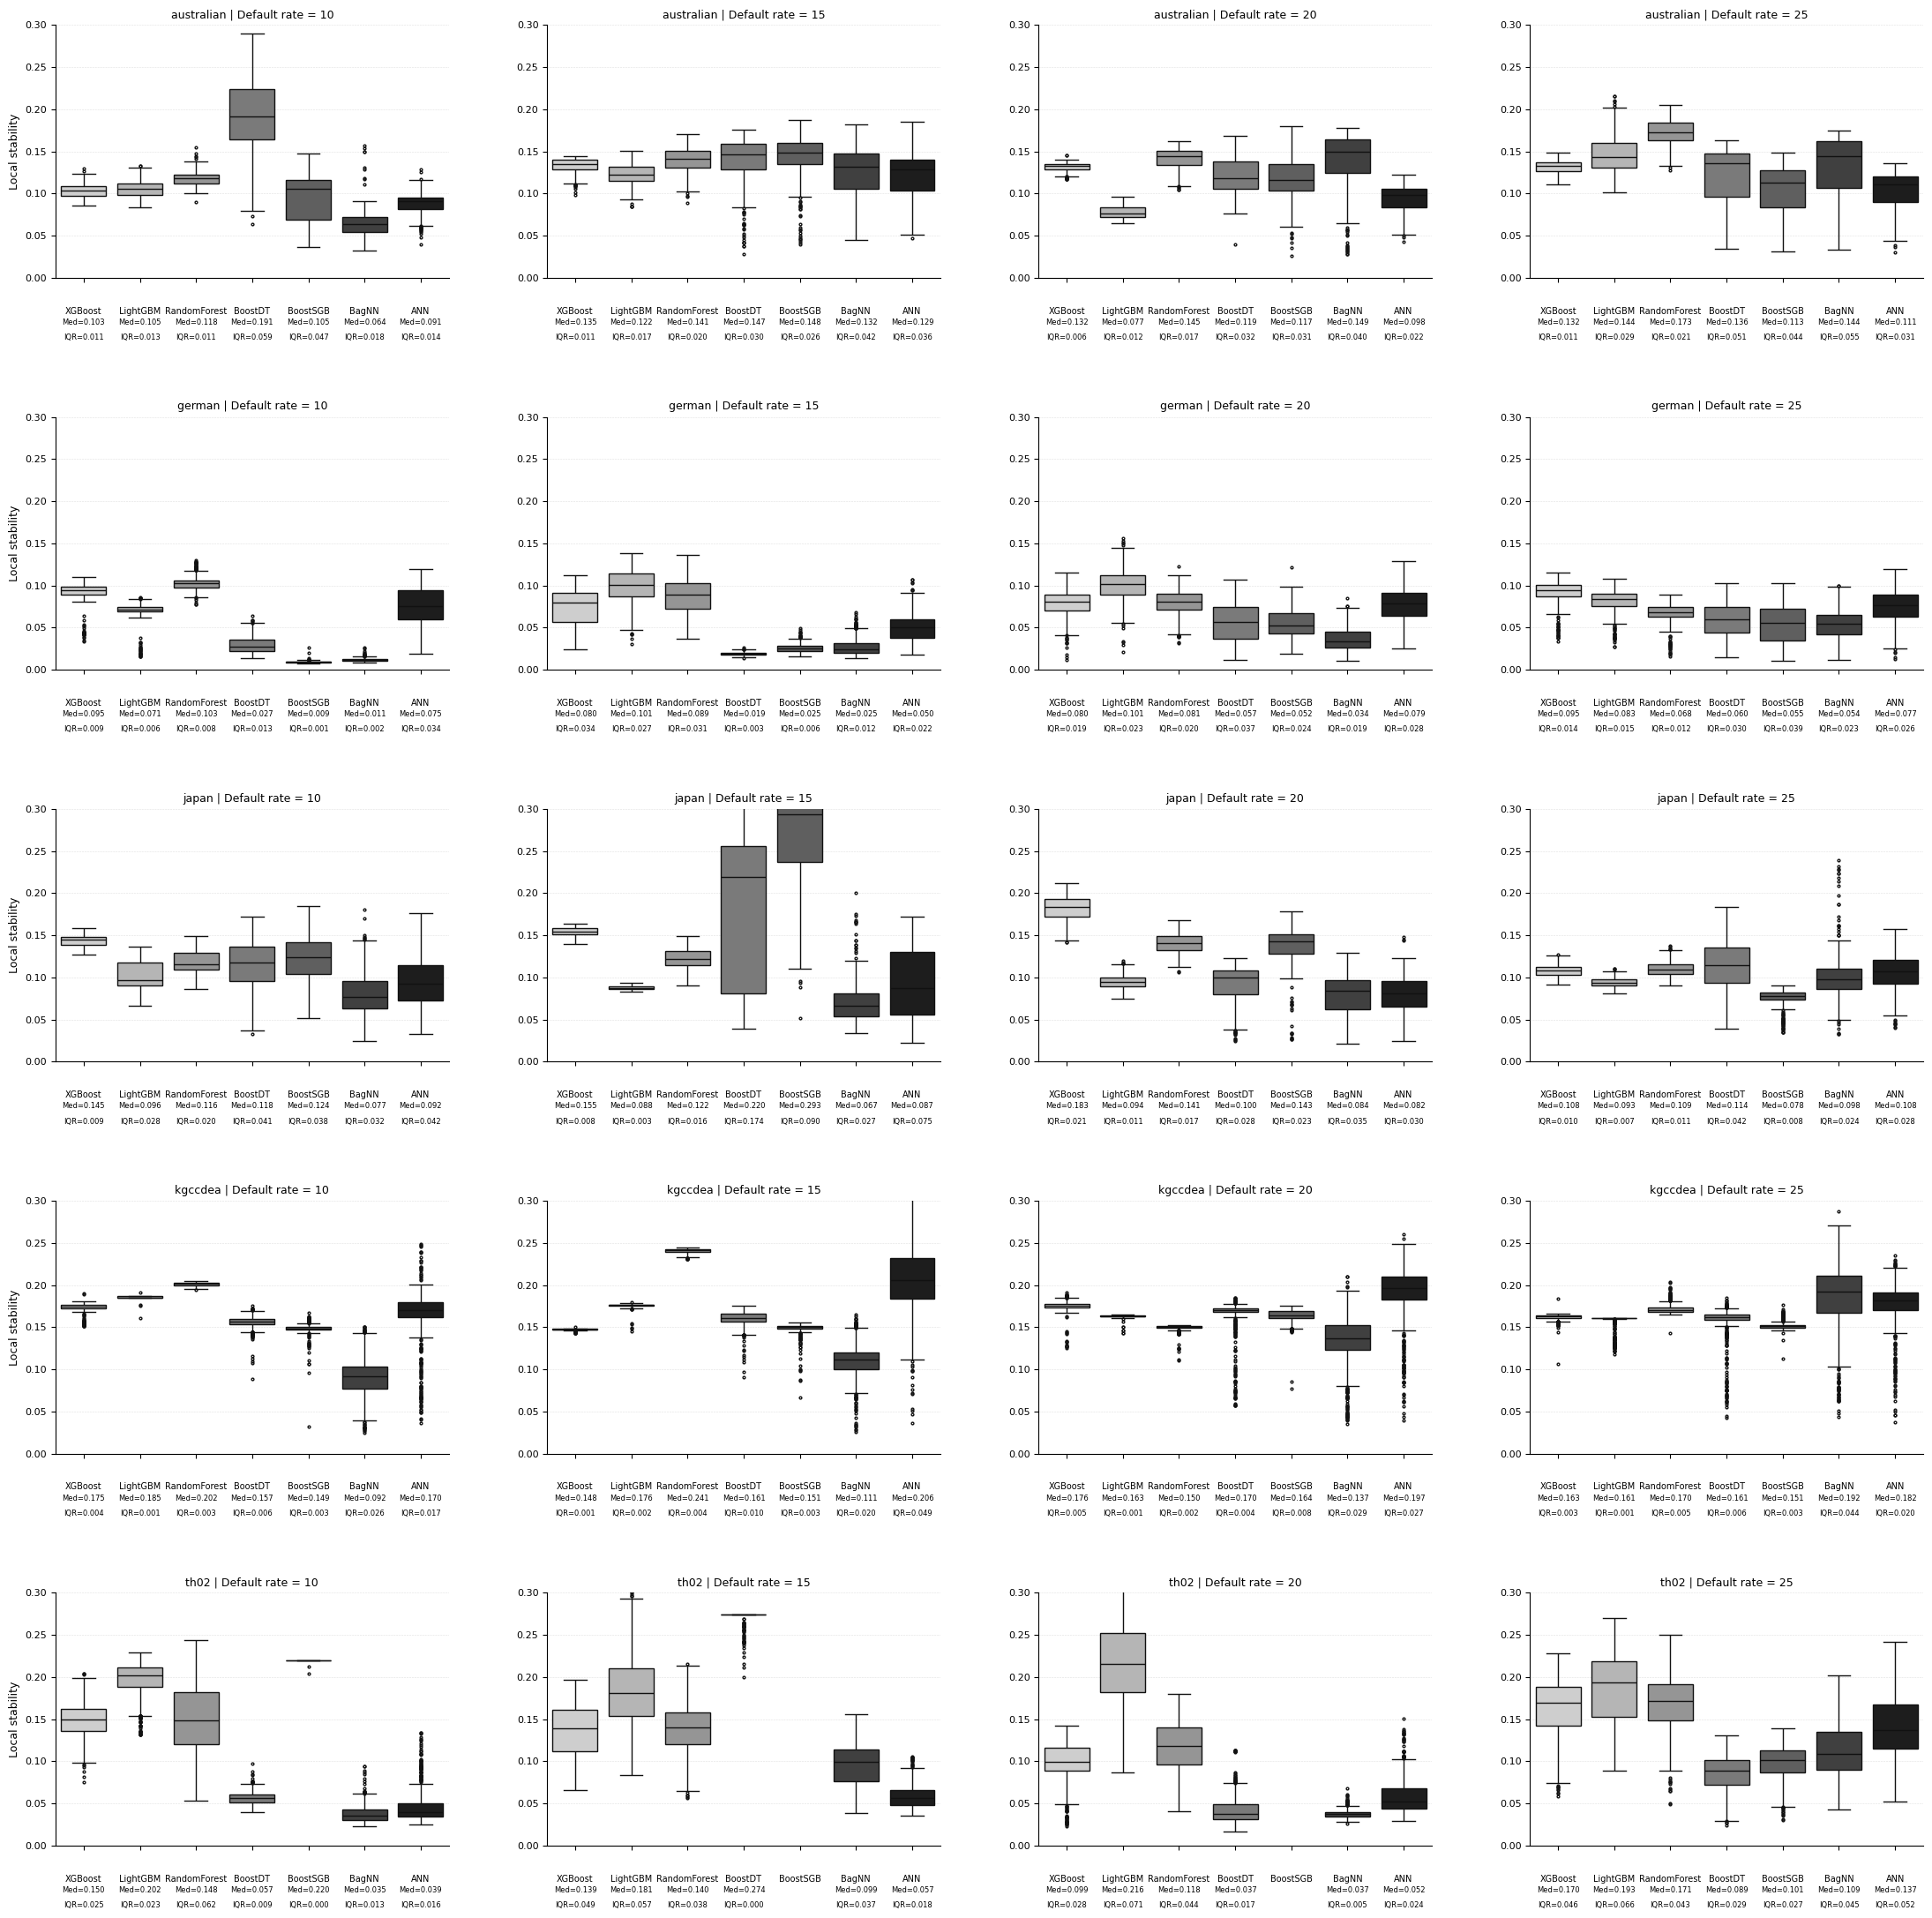

In [5]:
fig, axes = plot_models_by_imbalance(
    df=df_local,
    datasets=datasets_to_run,
    models=model_choices,
    imbalance_levels=imbalance_levels,
    metric="rankstab_local_weight",
    ylabel="Local stability",
    xlabel="",
    suptitle="",
    ylim=(0, 0.3)
)

fig.savefig(
    "figure_1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
output_dir = data_dir / "output"

df_details = pd.read_csv(output_dir / "resume_performance_details.csv")

df_plot = (
    df_details
    .groupby(["dataset", "model", "imbalance"], as_index=False)["pr_auc"]
    .mean()
)

In [18]:
df_plot

,dataset,model,imbalance,pr_auc
0,australian,ANN,10,0.608053
1,australian,ANN,15,0.680309
2,australian,ANN,20,0.801519
3,australian,ANN,25,0.843730
4,australian,BagNN,10,0.550584
...,...,...,...,...
135,th02,RandomForest,25,0.331529
136,th02,XGBoost,10,0.163604
137,th02,XGBoost,15,0.229974
138,th02,XGBoost,20,0.320371


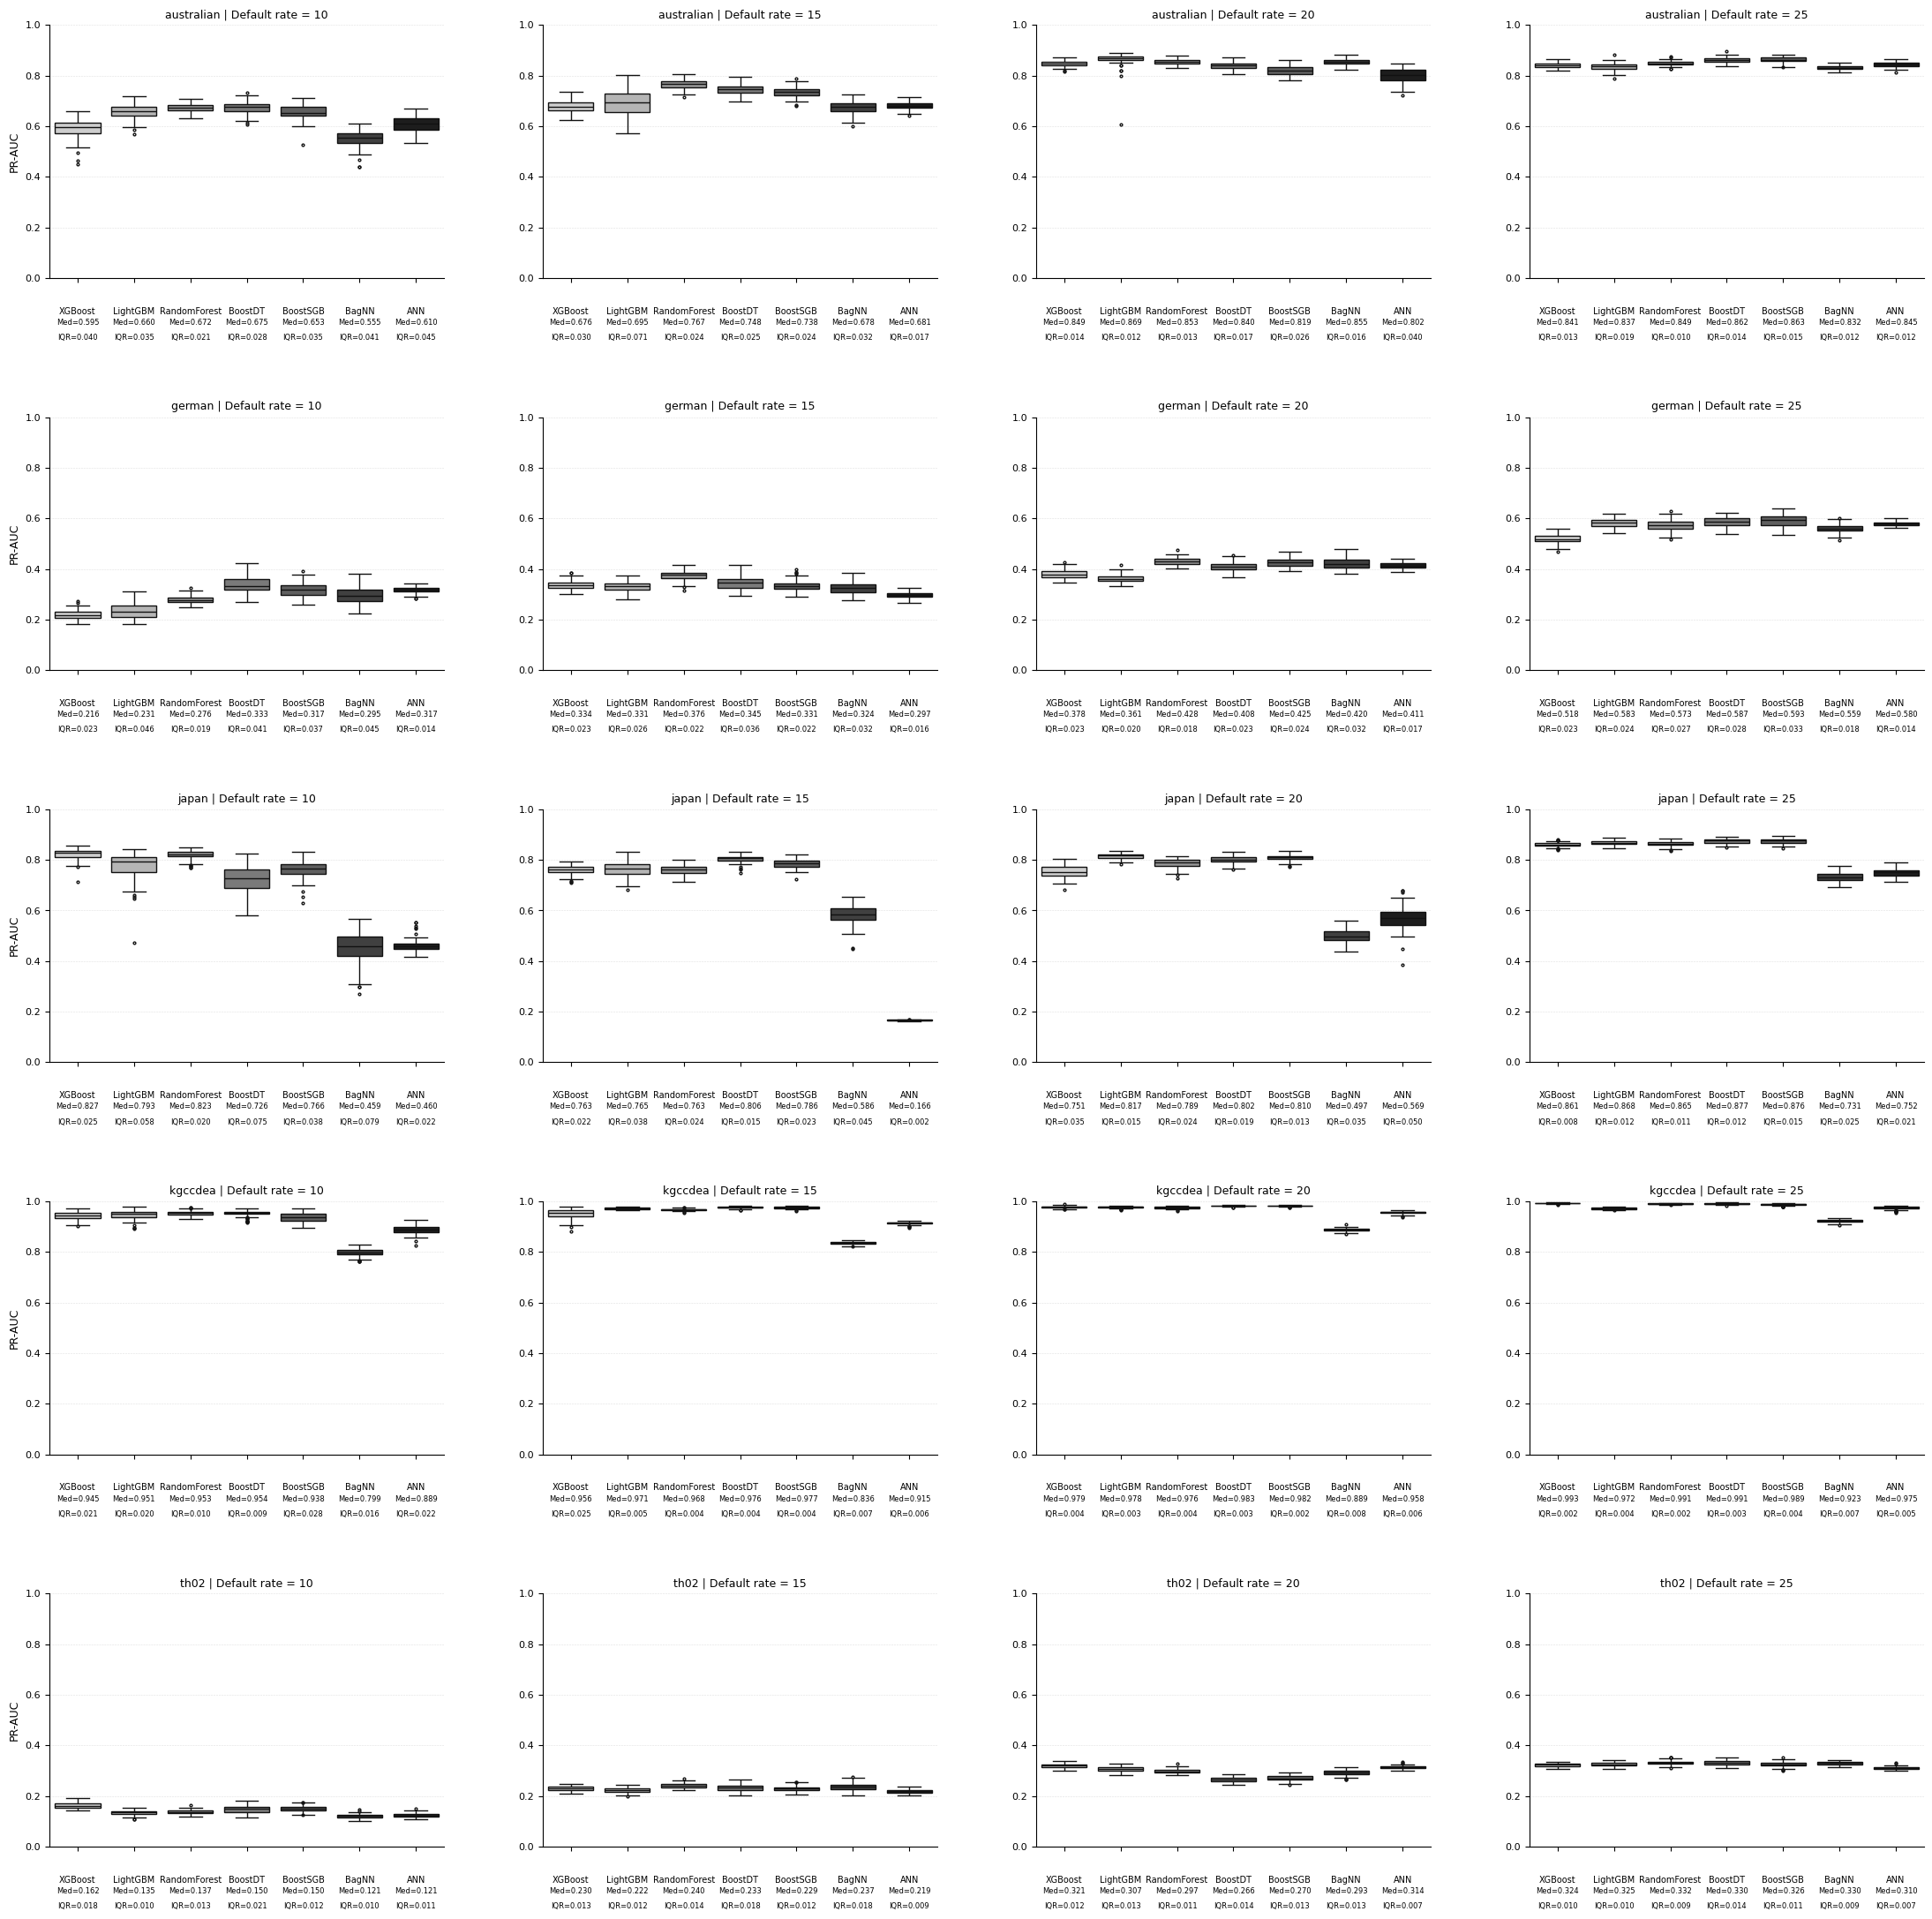

In [ ]:


fig, axes = plot_models_by_imbalance(
    df=df_details,
    datasets=datasets_to_run,
    models=model_choices,
    imbalance_levels=imbalance_levels,
    metric="pr_auc",
    ylabel="PR-AUC",
    xlabel="",
    suptitle="",
    ylim=(0.0, 1)  # more appropriate for PR-AUC
)

fig.savefig(
    "figure_3.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

,Model,AUC,PG,K-S,SMLI,SRA,CV
5,RandomForest,2.80,2.75,3.15,2.10,2.30,2.40
1,BagNN,5.75,5.30,5.35,5.80,3.65,5.05
0,ANN,5.45,4.90,4.60,5.10,2.05,4.35
6,XGBoost,4.25,4.40,3.90,2.15,5.50,3.30
4,LightGBM,4.00,4.40,3.60,2.70,5.20,3.45
2,BoostDT,2.65,3.10,3.05,5.00,4.35,4.70
3,BoostSGB,3.10,3.15,3.35,4.75,4.90,4.35


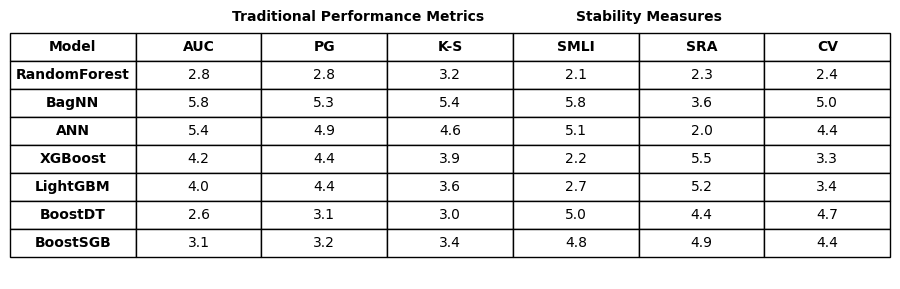

In [22]:
import pandas as pd
import matplotlib.pyplot as plt

# =====================================================
# READ MERGED CSV
# =====================================================

output_dir = data_dir / "output"

df_table = pd.read_csv(output_dir / "resume_model_rank_merged.csv")

# =====================================================
# SELECT + RENAME COLUMNS
# =====================================================

df_table = df_table[
    [
        "model",
        "rank_avg_pr_auc",
        "rank_avg_pg",
        "rank_avg_ks",
        "rank_rankstab_local",
        "rank_value_stab",
        "rank_rankstab_global",
    ]
].rename(
    columns={
        "model": "Model",
        "rank_avg_pr_auc": "AUC",
        "rank_avg_pg": "PG",
        "rank_avg_ks": "K-S",
        "rank_rankstab_local": "SMLI",
        "rank_value_stab": "SRA",
        "rank_rankstab_global": "CV",
    }
)

# =====================================================
# SORT MODELS
# =====================================================

model_order = [
    "RandomForest",
    "BagNN",
    "ANN",
    "XGBoost",
    "LightGBM",
    "BoostDT",
    "BoostSGB",
]

df_table["Model"] = pd.Categorical(
    df_table["Model"],
    categories=model_order,
    ordered=True,
)

df_table = df_table.sort_values("Model")
df_table["Model"] = df_table["Model"].astype(str)

# =====================================================
# DISPLAY DATAFRAME
# =====================================================

display(df_table)

# =====================================================
# VISUAL TABLE
# =====================================================

fig, ax = plt.subplots(figsize=(9, 3))
ax.axis("off")

table = ax.table(
    cellText=df_table.round(1).values,
    colLabels=df_table.columns,
    cellLoc="center",
    colLoc="center",
    loc="center",
)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.15, 1.45)

# Bold header row
for col in range(len(df_table.columns)):
    table[(0, col)].set_text_props(weight="bold")

# Bold model names
for row in range(1, len(df_table) + 1):
    table[(row, 0)].set_text_props(weight="bold")

# Group titles
ax.text(
    0.38,
    0.98,
    "Traditional Performance Metrics",
    ha="center",
    va="center",
    fontsize=10,
    weight="bold",
)

ax.text(
    0.76,
    0.98,
    "Stability Measures",
    ha="center",
    va="center",
    fontsize=10,
    weight="bold",
)

plt.tight_layout()
plt.show()

In [23]:
# =====================================================
# READ PERFORMANCE DETAILS
# =====================================================

df_perf_details = pd.read_csv(output_dir / "resume_performance_details.csv")

# =====================================================
# CREATE PR-AUC MEAN + STD TABLE
# =====================================================

df_pr_auc_table = (
    df_perf_details
    .groupby("model", as_index=False)
    .agg(
        pr_auc_mean=("pr_auc", "mean"),
        pr_auc_std=("pr_auc", "std"),
        pr_auc_var=("pr_auc", "var"),
    )
)

# Optional: keep only mean + std
df_pr_auc_table = df_pr_auc_table[
    ["model", "pr_auc_mean", "pr_auc_std"]
].rename(
    columns={
        "model": "Model",
        "pr_auc_mean": "PR-AUC mean",
        "pr_auc_std": "PR-AUC std",
    }
)

# =====================================================
# SORT MODELS
# =====================================================

df_pr_auc_table["Model"] = pd.Categorical(
    df_pr_auc_table["Model"],
    categories=model_order,
    ordered=True,
)

df_pr_auc_table = df_pr_auc_table.sort_values("Model")
df_pr_auc_table["Model"] = df_pr_auc_table["Model"].astype(str)

display(df_pr_auc_table)

,Model,PR-AUC mean,PR-AUC std
5,RandomForest,0.645979,0.278218
1,BagNN,0.560016,0.241823
0,ANN,0.559333,0.274399
6,XGBoost,0.625294,0.280812
4,LightGBM,0.631926,0.285288
2,BoostDT,0.643790,0.278572
3,BoostSGB,0.641565,0.278095


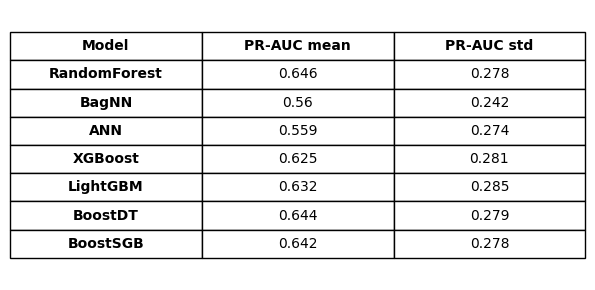

In [24]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.axis("off")

table = ax.table(
    cellText=df_pr_auc_table.round(3).values,
    colLabels=df_pr_auc_table.columns,
    cellLoc="center",
    colLoc="center",
    loc="center",
)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.15, 1.45)

for col in range(len(df_pr_auc_table.columns)):
    table[(0, col)].set_text_props(weight="bold")

for row in range(1, len(df_pr_auc_table) + 1):
    table[(row, 0)].set_text_props(weight="bold")

plt.tight_layout()
plt.show()

In [9]:
import pandas as pd

# =====================================================
# READ MERGED CSV
# =====================================================

output_dir = data_dir / "output"

df_latex = pd.read_csv(output_dir / "resume_model_rank_merged.csv")

# =====================================================
# SELECT + RENAME COLUMNS
# =====================================================

df_latex = df_latex[
    [
        "model",
        "rank_avg_pr_auc",
        "rank_avg_pg",
        "rank_avg_ks",
        "rank_rankstab_local",
        "rank_value_stab",
        "rank_rankstab_global",
    ]
].rename(
    columns={
        "model": "Model",
        "rank_avg_pr_auc": "AUC",
        "rank_avg_pg": "PG",
        "rank_avg_ks": "K-S",
        "rank_rankstab_local": "SMLI",
        "rank_value_stab": "SRA",
        "rank_rankstab_global": "CV",
    }
)

# =====================================================
# SORT + SHORT MODEL NAMES
# =====================================================

model_name_map = {
    "RandomForest": "RF",
    "XGBoost": "XGB",
    "LightGBM": "LGBM",
    "BagNN": "BagNN",
    "ANN": "ANN",
    "BoostDT": "BoostDT",
    "BoostSGB": "BoostSGB",
}

model_order = [
    "RandomForest",
    "XGBoost",
    "LightGBM",
    "BoostSGB",
    "BoostDT",
    "ANN",
    "BagNN",
]

df_latex["Model"] = pd.Categorical(
    df_latex["Model"],
    categories=model_order,
    ordered=True,
)

df_latex = df_latex.sort_values("Model")
df_latex["Model"] = df_latex["Model"].astype(str).replace(model_name_map)

# =====================================================
# ROUND VALUES
# =====================================================

metric_cols = ["AUC", "PG", "K-S", "SMLI", "SRA", "CV"]
df_latex[metric_cols] = df_latex[metric_cols].round(1)

# =====================================================
# GENERATE LATEX TABLE
# =====================================================

latex_rows = []

for _, row in df_latex.iterrows():
    latex_rows.append(
        f"{row['Model']:<8} & "
        f"{row['AUC']:.1f} & "
        f"{row['PG']:.1f} & "
        f"{row['K-S']:.1f} & "
        f"{row['SMLI']:.1f} & "
        f"{row['SRA']:.1f} & "
        f"{row['CV']:.1f} \\\\"
    )

latex_table = r"""
\begin{table}[!ht]
\centering
\caption{Performance Metrics and Stability Measures for Different Models}
\label{tab:ResultsBenchTable}

\begin{adjustbox}{max width=\columnwidth}
\begin{tabular}{lcccccc}
\toprule
& \multicolumn{3}{c}{\textbf{Traditional Performance Metrics}}
& \multicolumn{3}{c}{\textbf{Stability Measures}} \\
\cmidrule(lr){2-4} \cmidrule(lr){5-7}
\textbf{Model} & \textbf{AUC} & \textbf{PG} & \textbf{K-S}
& \textbf{SMLI} & \textbf{SRA} & \textbf{CV} \\
\midrule
""" + "\n".join(latex_rows) + r"""
\bottomrule
\end{tabular}
\end{adjustbox}
\end{table}
"""

print(latex_table)

# Optional: save as .tex file
with open(output_dir / "results_benchmark_table.tex", "w") as f:
    f.write(latex_table)

print("[OK] LaTeX table saved to:", output_dir / "results_benchmark_table.tex")


\begin{table}[!ht]
\centering
\caption{Performance Metrics and Stability Measures for Different Models}
\label{tab:ResultsBenchTable}

\begin{adjustbox}{max width=\columnwidth}
\begin{tabular}{lcccccc}
\toprule
& \multicolumn{3}{c}{\textbf{Traditional Performance Metrics}}
& \multicolumn{3}{c}{\textbf{Stability Measures}} \\
\cmidrule(lr){2-4} \cmidrule(lr){5-7}
\textbf{Model} & \textbf{AUC} & \textbf{PG} & \textbf{K-S}
& \textbf{SMLI} & \textbf{SRA} & \textbf{CV} \\
\midrule
RF       & 2.8 & 2.8 & 3.2 & 2.1 & 2.3 & 2.4 \\
XGB      & 4.2 & 4.4 & 3.9 & 2.2 & 5.5 & 3.3 \\
LGBM     & 4.0 & 4.4 & 3.6 & 2.7 & 5.2 & 3.4 \\
BoostSGB & 3.1 & 3.2 & 3.4 & 4.8 & 4.9 & 4.4 \\
BoostDT  & 2.6 & 3.1 & 3.0 & 5.0 & 4.4 & 4.7 \\
ANN      & 5.4 & 4.9 & 4.6 & 5.1 & 2.0 & 4.4 \\
BagNN    & 5.8 & 5.3 & 5.4 & 5.8 & 3.6 & 5.0 \\
\bottomrule
\end{tabular}
\end{adjustbox}
\end{table}

[OK] LaTeX table saved to: /Users/eduardohome/workspace/benchmark_credit_scoring/data/output/results_benchmark_table.tex


In [10]:
import pandas as pd

output_dir = data_dir / "output"

# =====================================================
# LOAD BOTH DATASET-LEVEL FILES
# =====================================================

df_perf = pd.read_csv(output_dir / "resume_performance_model_dataset_rank.csv")
df_stab = pd.read_csv(output_dir / "resume_stability_model_dataset_rank.csv")

# =====================================================
# MERGE
# =====================================================

df = pd.merge(
    df_perf,
    df_stab,
    on=["dataset", "model"],
    how="inner"
)

# =====================================================
# KEEP COLUMNS LIKE YOUR PICTURE
# =====================================================

df = df[
    [
        "dataset",
        "model",
        "rank_avg_pr_auc",
        "rank_avg_pg",
        "rank_avg_ks",
        "rank_rankstab_local",
        "rank_value_stab",
        "rank_rankstab_global",
    ]
].rename(
    columns={
        "model": "Model",
        "rank_avg_pr_auc": "AUC",
        "rank_avg_pg": "PG",
        "rank_avg_ks": "K-S",
        "rank_rankstab_local": "SMLI",
        "rank_value_stab": "SRA",
        "rank_rankstab_global": "CV",
    }
)

# =====================================================
# MODEL NAMES + ORDER
# =====================================================

model_name_map = {
    "RandomForest": "RF",
    "XGBoost": "XGB",
    "LightGBM": "LGBM",
}

model_order = [
    "RandomForest",
    "XGBoost",
    "LightGBM",
    "BoostSGB",
    "BoostDT",
    "ANN",
    "BagNN",
]

metric_cols = ["AUC", "PG", "K-S", "SMLI", "SRA", "CV"]

# =====================================================
# BUILD MULTI-PANEL LATEX TABLE
# =====================================================

latex_blocks = []

for dataset_name, df_dataset in df.groupby("dataset"):

    df_tmp = df_dataset.copy()

    df_tmp["Model"] = pd.Categorical(
        df_tmp["Model"],
        categories=model_order,
        ordered=True
    )

    df_tmp = df_tmp.sort_values("Model")
    df_tmp["Model"] = df_tmp["Model"].astype(str).replace(model_name_map)
    df_tmp[metric_cols] = df_tmp[metric_cols].round(1)

    dataset_label = dataset_name.replace("_", " ").title()

    latex_blocks.append(
        rf"\multicolumn{{7}}{{l}}{{\textbf{{{dataset_label} credit data}}}} \\"
    )

    for _, row in df_tmp.iterrows():
        latex_blocks.append(
            f"{row['Model']:<8} & "
            f"{row['AUC']:.1f} & "
            f"{row['PG']:.1f} & "
            f"{row['K-S']:.1f} & "
            f"{row['SMLI']:.1f} & "
            f"{row['SRA']:.1f} & "
            f"{row['CV']:.1f} \\\\"
        )

    latex_blocks.append(r"\addlinespace")

latex_blocks = latex_blocks[:-1]

latex_table = r"""
\begin{table}[!ht]
\centering
\caption{Performance Metrics and Stability Measures Across Credit Datasets}
\label{tab:ResultsBenchMultiDataset}

\begin{adjustbox}{max width=\columnwidth}
\begin{tabular}{lcccccc}
\toprule
& \multicolumn{3}{c}{\textbf{Traditional Performance Metrics}}
& \multicolumn{3}{c}{\textbf{Stability Measures}} \\
\cmidrule(lr){2-4} \cmidrule(lr){5-7}
\textbf{Model} & \textbf{AUC} & \textbf{PG} & \textbf{K-S}
& \textbf{SMLI} & \textbf{SRA} & \textbf{CV} \\
\midrule
""" + "\n".join(latex_blocks) + r"""
\bottomrule
\end{tabular}
\end{adjustbox}
\end{table}
"""

print(latex_table)

with open(output_dir / "latex_table_all_datasets.tex", "w") as f:
    f.write(latex_table)


\begin{table}[!ht]
\centering
\caption{Performance Metrics and Stability Measures Across Credit Datasets}
\label{tab:ResultsBenchMultiDataset}

\begin{adjustbox}{max width=\columnwidth}
\begin{tabular}{lcccccc}
\toprule
& \multicolumn{3}{c}{\textbf{Traditional Performance Metrics}}
& \multicolumn{3}{c}{\textbf{Stability Measures}} \\
\cmidrule(lr){2-4} \cmidrule(lr){5-7}
\textbf{Model} & \textbf{AUC} & \textbf{PG} & \textbf{K-S}
& \textbf{SMLI} & \textbf{SRA} & \textbf{CV} \\
\midrule
\multicolumn{7}{l}{\textbf{Australian credit data}} \\
RF       & 2.0 & 2.2 & 3.0 & 1.5 & 1.0 & 1.0 \\
XGB      & 5.2 & 5.0 & 3.8 & 1.8 & 6.5 & 2.5 \\
LGBM     & 3.5 & 3.8 & 3.5 & 4.0 & 5.8 & 4.5 \\
BoostSGB & 3.5 & 2.5 & 4.8 & 5.0 & 3.8 & 3.5 \\
BoostDT  & 2.5 & 2.5 & 2.5 & 4.0 & 5.0 & 4.5 \\
ANN      & 5.2 & 5.5 & 4.0 & 6.5 & 2.5 & 6.5 \\
BagNN    & 6.0 & 6.5 & 6.5 & 5.2 & 3.5 & 5.5 \\
\addlinespace
\multicolumn{7}{l}{\textbf{German credit data}} \\
RF       & 3.0 & 2.8 & 3.2 & 1.8 & 3.8 & 3.2 \\
XGB  